# Sentinel: Predicting Cancer Drug Sensitivity from Tumour Genomics
Veritas AI International High School Hackathon 2026 · AI + Health track

This project is a prototype and is not medical advice. All data comes from cancer cell lines grown in the lab, not from patients.

**Who it is for:** A cancer biology researcher or molecular tumour board analyst who has just sequenced a tumour cell line and needs to decide which cancer drugs to test first in the wet lab, rather than screening hundreds of compounds by hand.

This notebook covers the whole project: downloading and checking the data, exploring it, splitting it by cell line, comparing simple baselines with a LightGBM model on cell lines the models have never seen, checking missed cases and subgroup gaps, testing where the model fails, and exploring single-gene what-if toggles in an interactive Gradio demo. Run everything with *Runtime -> Run all*.

## 1. Setup

In [1]:
import os
import urllib.request
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, confusion_matrix

warnings.filterwarnings("ignore", category=RuntimeWarning)
sns.set_theme(style="whitegrid")

os.makedirs("data/raw", exist_ok=True)
os.makedirs("figures", exist_ok=True)

## 2. Download the data
All files come from the Wellcome Sanger Institute (Cell Model Passports). Sanger's usage policy doesn't allow us to re-share the files, so the notebook downloads them directly instead of keeping them in our repository. Sources and citations are listed in `data/DATA_SOURCES.md`.

In [2]:
FILES = {
    "GDSC2_fitted_dose_response_27Oct23.xlsx": "https://cmp.cog.sanger.ac.uk/download/GDSC2_fitted_dose_response_27Oct23.xlsx",
    "model_list_20261013.csv": "https://cog.sanger.ac.uk/cmp/download/model_list_20261013.csv",
    "mutations_summary_20260724.zip": "https://cog.sanger.ac.uk/cmp/download/mutations_summary_20260724.zip",
    "model_dataset_availability_20260727.csv": "https://cog.sanger.ac.uk/cmp/download/model_dataset_availability_20260727.csv",
}

for name, url in FILES.items():
    path = "data/raw/" + name
    if not os.path.exists(path):  # skip files we already downloaded
        print("downloading", name)
        urllib.request.urlretrieve(url, path)

## 3. Load the tables

In [3]:
response = pd.read_excel("data/raw/GDSC2_fitted_dose_response_27Oct23.xlsx")   # drug responses (LN_IC50)
models = pd.read_csv("data/raw/model_list_20261013.csv", low_memory=False)     # cell line info (tissue, sex, age)
mutations = pd.read_csv("data/raw/mutations_summary_20260724.zip")              # driver mutations per cell line
available = pd.read_csv("data/raw/model_dataset_availability_20260727.csv")     # which cell lines were sequenced

for name, table in [("response", response), ("models", models), ("mutations", mutations), ("available", available)]:
    print(f"{name}: {table.shape[0]:,} rows, {table.shape[1]} columns")

response.head(3)

response: 242,036 rows, 16 columns
models: 2,292 rows, 110 columns
mutations: 15,025 rows, 20 columns
available: 2,039 rows, 25 columns


,DATASET,NLME_RESULT_ID,NLME_CURVE_ID,CELL_LINE_NAME,SANGER_MODEL_ID,CANCER_TYPE,DRUG_ID,DRUG_NAME,PUTATIVE_TARGET,PATHWAY_NAME,MIN_CONC,MAX_CONC,LN_IC50,AUC,RMSE,Z_SCORE
0,GDSC2,343,15946310,PFSK-1,SIDM01132,Other Solid Cancers,1003,Camptothecin,TOP1,DNA replication,0.0001,0.1,-1.463887,0.930220,0.089052,0.433123
1,GDSC2,343,15946548,A673,SIDM00848,Ewing's Sarcoma,1003,Camptothecin,TOP1,DNA replication,0.0001,0.1,-4.869455,0.614970,0.111351,-1.421100
2,GDSC2,343,15946830,ES5,SIDM00263,Ewing's Sarcoma,1003,Camptothecin,TOP1,DNA replication,0.0001,0.1,-3.360586,0.791072,0.142855,-0.599569


## 4. Data checks
GDSC2 calls the cell line ID `SANGER_MODEL_ID`; the other files call it `model_id`. We only keep cell lines that were sequenced, because for an unsequenced cell line a missing mutation doesn't mean the gene is normal.

In [4]:
print("cell lines:", response["SANGER_MODEL_ID"].nunique())
print("drug IDs:", response["DRUG_ID"].nunique())
print("missing LN_IC50 values:", response["LN_IC50"].isna().sum())
print("duplicate cell line + drug pairs:", response.duplicated(["SANGER_MODEL_ID", "DRUG_ID"]).sum())

ids = response["SANGER_MODEL_ID"].drop_duplicates()
print("cell lines found in the model list:", ids.isin(models["model_id"]).sum())

seq_columns = ["Mutation Sanger Cell Lines (WES)", "Mutation Broad Cell Lines (WES)", "Mutation Sanger Cell Lines (WGS)"]
sequenced = available[available[seq_columns].any(axis=1)]["model_id"]
print("cell lines that were sequenced:", ids.isin(sequenced).sum())

# a few cell lines are not cancer cell lines - we remove them before modelling
non_cancer = models[models["cancer_type"].str.contains("Non-Cancerous", na=False) & models["model_id"].isin(ids)]
print("non-cancer cell lines:", len(non_cancer), list(non_cancer["model_name"]))

# some drugs were screened twice under different IDs, so DRUG_ID is used as the key, not the name
ids_per_name = response.groupby("DRUG_NAME")["DRUG_ID"].nunique()
print("drug names with more than one ID:", list(ids_per_name[ids_per_name > 1].index))

cell lines: 969
drug IDs: 295
missing LN_IC50 values: 0
duplicate cell line + drug pairs: 0
cell lines found in the model list: 969
cell lines that were sequenced: 965
non-cancer cell lines: 7 ['BPH-1', 'Hs-445', 'ARH-77', 'IM-9', 'PWR-1E', 'RPMI-6666', 'WIL2-NS']
drug names with more than one ID: ['Acetalax', 'Dactinomycin', 'Docetaxel', 'Fulvestrant', 'GSK343', 'Oxaliplatin', 'Selumetinib', 'Ulixertinib', 'Uprosertib']


## 5. Build the clean table

In [5]:
data = response[response["SANGER_MODEL_ID"].isin(sequenced)]

tissue = models[["model_id", "tissue"]].rename(columns={"model_id": "SANGER_MODEL_ID"})
data = data.merge(tissue, on="SANGER_MODEL_ID", how="left")
print("cell lines kept:", data["SANGER_MODEL_ID"].nunique(), "| missing tissue:", data["tissue"].isna().sum())

# mutation matrix: one row per cell line, one column per gene, 1 = mutated
cell_lines = data["SANGER_MODEL_ID"].unique()
mut = mutations[mutations["model_id"].isin(cell_lines)]
mut_matrix = pd.crosstab(mut["model_id"], mut["gene_symbol"]).clip(upper=1)
mut_matrix = mut_matrix.reindex(cell_lines, fill_value=0)  # sequenced lines with no listed mutations get all zeros
mut_matrix.index.name = "SANGER_MODEL_ID"
print("mutation matrix:", mut_matrix.shape[0], "cell lines x", mut_matrix.shape[1], "genes")


cell lines kept: 965 | missing tissue: 0
mutation matrix: 965 cell lines x 597 genes


## 6. Exploring the data
### Cell lines per tissue

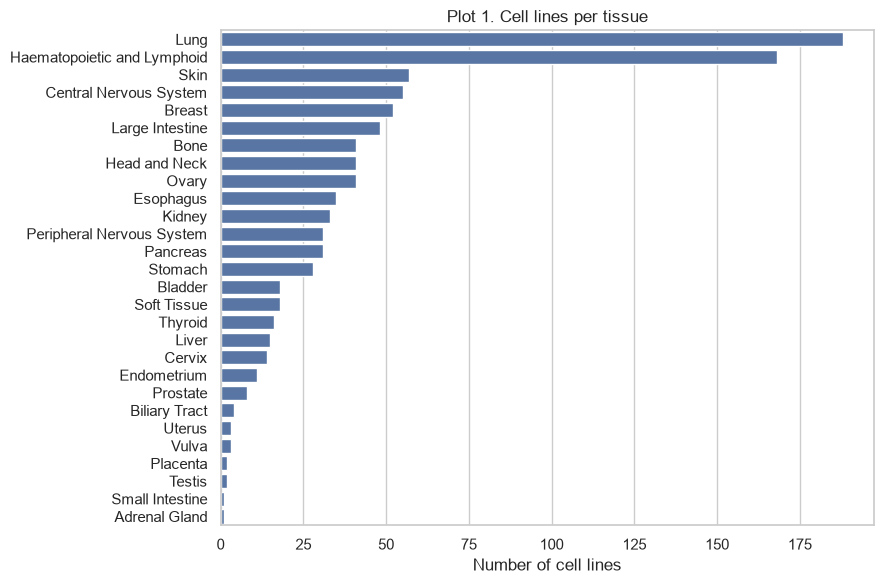

tissue
Lung                           188
Haematopoietic and Lymphoid    168
Skin                            57
Central Nervous System          55
Breast                          52
Large Intestine                 48
Bone                            41
Head and Neck                   41
Ovary                           41
Esophagus                       35
Kidney                          33
Peripheral Nervous System       31
Pancreas                        31
Stomach                         28
Bladder                         18
Soft Tissue                     18
Thyroid                         16
Liver                           15
Cervix                          14
Endometrium                     11
Prostate                         8
Biliary Tract                    4
Uterus                           3
Vulva                            3
Placenta                         2
Testis                           2
Small Intestine                  1
Adrenal Gland                    1


In [6]:
tissue_counts = data.drop_duplicates("SANGER_MODEL_ID")["tissue"].value_counts()

plt.figure(figsize=(9, 6))
sns.barplot(x=tissue_counts.values, y=tissue_counts.index)
plt.xlabel("Number of cell lines")
plt.ylabel("")
plt.title("Plot 1. Cell lines per tissue")
plt.tight_layout()
plt.savefig("figures/plot1_cell_lines_per_tissue.png", dpi=150)
plt.show()

print(tissue_counts.to_string())

Lung (188) and blood cancers (168) make up the largest groups. Breast (52) and large intestine/colorectal (48) also have enough cell lines for case studies. Some tissues have very few cell lines (prostate 8, biliary tract 4), so any result for those tissues on their own won't be reliable.

### Distribution of drug sensitivity (ln IC50)

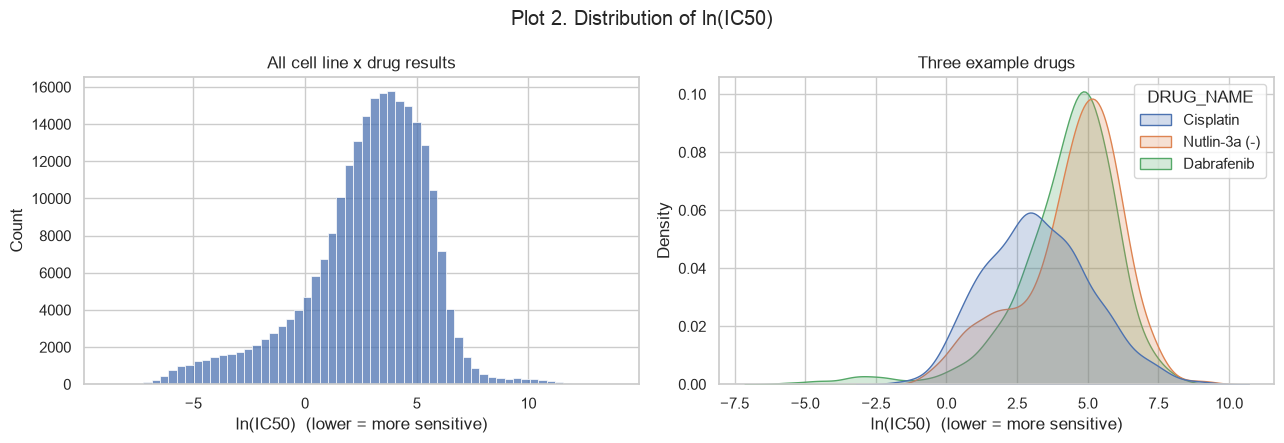

count    241030.00
mean          2.82
std           2.76
min          -8.75
25%           1.51
50%           3.24
75%           4.70
max          13.82
DRUG_NAME
Cisplatin        3.23
Dabrafenib       4.25
Nutlin-3a (-)    4.42
results above the highest tested dose: 71.8 %


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(data["LN_IC50"], bins=60, ax=axes[0])
axes[0].set_title("All cell line x drug results")
axes[0].set_xlabel("ln(IC50)  (lower = more sensitive)")

# 1373 = Dabrafenib, 1047 = Nutlin-3a, 1005 = Cisplatin
examples = data[data["DRUG_ID"].isin([1373, 1047, 1005])]
sns.kdeplot(data=examples, x="LN_IC50", hue="DRUG_NAME", fill=True, ax=axes[1])
axes[1].set_title("Three example drugs")
axes[1].set_xlabel("ln(IC50)  (lower = more sensitive)")

fig.suptitle("Plot 2. Distribution of ln(IC50)")
plt.tight_layout()
plt.savefig("figures/plot2_ln_ic50_distribution.png", dpi=150)
plt.show()

print(data["LN_IC50"].describe().round(2).to_string())
print(examples.groupby("DRUG_NAME")["LN_IC50"].mean().round(2).to_string())

# IC50 above the highest tested dose means the value was extrapolated from the fitted curve
above_max = data["LN_IC50"] > np.log(data["MAX_CONC"])
print("results above the highest tested dose:", round(above_max.mean() * 100, 1), "%")

Across 241,030 results, ln(IC50) ranges from about -8.8 to 13.8 with a median of 3.24; the middle half lies between 1.51 and 4.70. Each drug has its own typical range (mean 3.23 for Cisplatin, 4.25 for Dabrafenib, 4.42 for Nutlin-3a) because every drug was tested at its own doses. So raw values shouldn't be compared directly across drugs, and any baseline has to at least predict each drug's average.

In 71.8% of results the IC50 is above the highest dose actually tested, meaning 50% inhibition wasn't reached and the value is an estimate from the fitted curve. We keep these results but treat them as less certain.